# Shopify Stock Market Analysis & Financial EDA  (30/10/26)

## 1. Introduction ##

This project focuses on Exploratory Data Analysis (EDA) of Shopify Stock Market Data.

# 2. Objectives #

* Understand stock market data.
* Clean and preprocess the dataset.
* daily stock price changes.
* Calculate daily returns.
* Analyze trading volume.
* Identify price fluctuations and outliers.
* Visualize stock market trends.

# 3. Libraries Used #

* Pandas
* NumPy
* Matplotlib
* Seaborn

## Import libraries ##

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


## Load the original dataset ##

In [4]:
df = pd.read_csv(r"C:\Users\Dell\Downloads\SHOP_2015-05-21_2025-03-16.csv")
print("Data loaded Successully") 

Data loaded Successully


In [5]:
df.head()

,date,open,high,low,close,adj_close,volume
0,2015-05-21 00:00:00-04:00,2.800,2.874,2.411,2.568,2.568,123039000
1,2015-05-22 00:00:00-04:00,2.607,3.110,2.600,2.831,2.831,28412000
2,2015-05-26 00:00:00-04:00,2.980,3.034,2.908,2.965,2.965,8202000
3,2015-05-27 00:00:00-04:00,3.067,3.081,2.700,2.750,2.750,7976000
4,2015-05-28 00:00:00-04:00,2.755,2.774,2.648,2.745,2.745,4000000


## Check dataset dimensions ##

In [6]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 2469
Number of Columns: 7


## Display column names ##

In [7]:
print("Column Names:")

print(df.columns)

Column Names:
Index(['date', 'open', 'high', 'low', 'close', 'adj_close', 'volume'], dtype='object')


## Check dataset information ##

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2469 entries, 0 to 2468
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       2469 non-null   object 
 1   open       2469 non-null   float64
 2   high       2469 non-null   float64
 3   low        2469 non-null   float64
 4   close      2469 non-null   float64
 5   adj_close  2469 non-null   float64
 6   volume     2469 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 135.2+ KB


## Generate statistical summary ##

In [10]:
df.describe()

,open,high,low,close,adj_close,volume
count,2469.000000,2469.000000,2469.000000,2469.000000,2469.000000,2.469000e+03
mean,48.464345,49.505495,47.347795,48.456613,48.456613,1.657049e+07
std,43.633916,44.470235,42.642546,43.573362,43.573362,1.436909e+07
min,1.939000,1.985000,1.848000,1.933000,1.933000,1.039000e+06
25%,10.479000,10.635000,10.275000,10.450000,10.450000,8.098000e+06
50%,35.640999,36.879002,34.655998,35.874001,35.874001,1.275860e+07
75%,76.080002,77.169998,74.589996,75.800003,75.800003,2.060200e+07
max,171.800003,176.291794,168.509506,169.059998,169.059998,2.089590e+08


## Check first and last records ##

In [11]:
print("First 5 Records:")
display(df.head())

print("Last 5 Records:")
display(df.tail())

First 5 Records:


,date,open,high,low,close,adj_close,volume
0,2015-05-21 00:00:00-04:00,2.800,2.874,2.411,2.568,2.568,123039000
1,2015-05-22 00:00:00-04:00,2.607,3.110,2.600,2.831,2.831,28412000
2,2015-05-26 00:00:00-04:00,2.980,3.034,2.908,2.965,2.965,8202000
3,2015-05-27 00:00:00-04:00,3.067,3.081,2.700,2.750,2.750,7976000
4,2015-05-28 00:00:00-04:00,2.755,2.774,2.648,2.745,2.745,4000000


Last 5 Records:


,date,open,high,low,close,adj_close,volume
2464,2025-03-10 00:00:00-04:00,96.070000,96.186996,91.690002,92.750000,92.750000,16385300
2465,2025-03-11 00:00:00-04:00,92.750000,95.109001,91.150002,92.949997,92.949997,12127100
2466,2025-03-12 00:00:00-04:00,96.669998,99.135002,95.290001,96.529999,96.529999,8531900
2467,2025-03-13 00:00:00-04:00,95.169998,95.529999,89.099998,90.589996,90.589996,11076400
2468,2025-03-14 00:00:00-04:00,94.610001,95.830002,93.059998,94.849998,94.849998,7060700


# Data Quality Checking #

## Check missing values ##

In [13]:
df.isnull().sum()

date         0
open         0
high         0
low          0
close        0
adj_close    0
volume       0
dtype: int64

## Check total missing values ##

In [14]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


## Check duplicate records ##

In [15]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


## Check data types ##

In [17]:
print("Column Data Types:")
print(df.dtypes)

Column Data Types:
date          object
open         float64
high         float64
low          float64
close        float64
adj_close    float64
volume         int64
dtype: object


## Display dataset shape again ##

In [18]:
print("Dataset Shape:", df.shape)


Dataset Shape: (2469, 7)


# Data Cleaning & Date Conversion #

## Convert date column ##

In [22]:
df['date'] = pd.to_datetime(df['date'])

C:\Users\Dell\AppData\Local\Temp\ipykernel_6776\3532345252.py:1: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  df['date'] = pd.to_datetime(df['date'])


## verify the conversion ##

In [23]:
print("Date Column Data Type:", df['date'].dtype)

Date Column Data Type: object


## Check the converted dates ##

In [24]:
df[['date']].head()

,date
0,2015-05-21 00:00:00-04:00
1,2015-05-22 00:00:00-04:00
2,2015-05-26 00:00:00-04:00
3,2015-05-27 00:00:00-04:00
4,2015-05-28 00:00:00-04:00


## Calculate Daily Price Change ##

In [25]:
df['daily_price_change'] = df['close'] - df['open']

df[['date', 'open', 'close', 'daily_price_change']].head()

,date,open,close,daily_price_change
0,2015-05-21 00:00:00-04:00,2.800,2.568,-0.232
1,2015-05-22 00:00:00-04:00,2.607,2.831,0.224
2,2015-05-26 00:00:00-04:00,2.980,2.965,-0.015
3,2015-05-27 00:00:00-04:00,3.067,2.750,-0.317
4,2015-05-28 00:00:00-04:00,2.755,2.745,-0.010


## Calculate Daily Return Percentage ##

In [26]:
df['daily_return'] = ((df['close'] - df['open']) / df['open']) * 100

df[['date', 'open', 'close', 'daily_return']].head()

,date,open,close,daily_return
0,2015-05-21 00:00:00-04:00,2.800,2.568,-8.285710
1,2015-05-22 00:00:00-04:00,2.607,2.831,8.592250
2,2015-05-26 00:00:00-04:00,2.980,2.965,-0.503359
3,2015-05-27 00:00:00-04:00,3.067,2.750,-10.335830
4,2015-05-28 00:00:00-04:00,2.755,2.745,-0.362985


## Check the new columns ##

In [28]:
print("Updated Dataset Shape:", df.shape)

print("\nNew Columns:")
print(df.columns)

Updated Dataset Shape: (2469, 9)

New Columns:
Index(['date', 'open', 'high', 'low', 'close', 'adj_close', 'volume',
       'daily_price_change', 'daily_return'],
      dtype='object')


## Display the updated dataset ##

In [29]:
df.head()

,date,open,high,low,close,adj_close,volume,daily_price_change,daily_return
0,2015-05-21 00:00:00-04:00,2.800,2.874,2.411,2.568,2.568,123039000,-0.232,-8.285710
1,2015-05-22 00:00:00-04:00,2.607,3.110,2.600,2.831,2.831,28412000,0.224,8.592250
2,2015-05-26 00:00:00-04:00,2.980,3.034,2.908,2.965,2.965,8202000,-0.015,-0.503359
3,2015-05-27 00:00:00-04:00,3.067,3.081,2.700,2.750,2.750,7976000,-0.317,-10.335830
4,2015-05-28 00:00:00-04:00,2.755,2.774,2.648,2.745,2.745,4000000,-0.010,-0.362985


# Trading Volume Analysis #

## Calculate Volume Statistics ##

In [30]:
print("Trading Volume Statistics")

print("Mean:", df['volume'].mean())
print("Median:", df['volume'].median())
print("Minimum:", df['volume'].min())
print("Maximum:", df['volume'].max())
print("Standard Deviation:", df['volume'].std())

Trading Volume Statistics
Mean: 16570491.778047793
Median: 12758600.0
Minimum: 1039000
Maximum: 208959000
Standard Deviation: 14369091.49927283


## Check Daily Trading Volume ##

In [31]:
volume_data = df[['date', 'volume']]

display(volume_data.head(10))


,date,volume
0,2015-05-21 00:00:00-04:00,123039000
1,2015-05-22 00:00:00-04:00,28412000
2,2015-05-26 00:00:00-04:00,8202000
3,2015-05-27 00:00:00-04:00,7976000
4,2015-05-28 00:00:00-04:00,4000000
5,2015-05-29 00:00:00-04:00,2554000
6,2015-06-01 00:00:00-04:00,2569000
7,2015-06-02 00:00:00-04:00,3798000
8,2015-06-03 00:00:00-04:00,3024000
9,2015-06-04 00:00:00-04:00,3226000


## Identify High and Low Trading Volume ##

In [33]:

highest_volume = df.loc[df['volume'].idxmax()]

lowest_volume = df.loc[df['volume'].idxmin()]

print("Highest Trading Volume:")
print(highest_volume[['date', 'volume']])

print("\nLowest Trading Volume:")
print(lowest_volume[['date', 'volume']])

Highest Trading Volume:
date      2017-10-04 00:00:00-04:00
volume                    208959000
Name: 598, dtype: object

Lowest Trading Volume:
date      2015-12-24 00:00:00-05:00
volume                      1039000
Name: 151, dtype: object


## Detect Unusual Trading Volume Using IQR ##

In [35]:
Q1 = df['volume'].quantile(0.25)
Q3 = df['volume'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)


Lower Bound: -10658000.0
Upper Bound: 39358000.0


## Identify unusual volume records: ##

In [36]:
volume_outliers = df[
    (df['volume'] < lower_bound) |
    (df['volume'] > upper_bound)
]

print("Number of Unusual Volume Records:", len(volume_outliers))

display(volume_outliers[['date', 'volume']].head(10))

Number of Unusual Volume Records: 136


,date,volume
0,2015-05-21 00:00:00-04:00,123039000
313,2016-08-17 00:00:00-04:00,58113000
410,2017-01-05 00:00:00-05:00,50702000
438,2017-02-15 00:00:00-05:00,56969000
490,2017-05-02 00:00:00-04:00,61484000
502,2017-05-18 00:00:00-04:00,79796000
503,2017-05-19 00:00:00-04:00,78909000
517,2017-06-09 00:00:00-04:00,46563000
518,2017-06-12 00:00:00-04:00,52444000
519,2017-06-13 00:00:00-04:00,39555000


# Price Fluctuation Analysis #

## Calculate Daily Price Range ##

In [37]:

df['daily_price_range'] = df['high'] - df['low']

df[['date', 'high', 'low', 'daily_price_range']].head()

,date,high,low,daily_price_range
0,2015-05-21 00:00:00-04:00,2.874,2.411,0.463
1,2015-05-22 00:00:00-04:00,3.110,2.600,0.510
2,2015-05-26 00:00:00-04:00,3.034,2.908,0.126
3,2015-05-27 00:00:00-04:00,3.081,2.700,0.381
4,2015-05-28 00:00:00-04:00,2.774,2.648,0.126


## Calculate Price Fluctuation Percentage ##

In [38]:
df['price_fluctuation_pct'] = (
    (df['high'] - df['low']) / df['low']
) * 100

df[['date', 'high', 'low', 'price_fluctuation_pct']].head()

,date,high,low,price_fluctuation_pct
0,2015-05-21 00:00:00-04:00,2.874,2.411,19.203652
1,2015-05-22 00:00:00-04:00,3.110,2.600,19.615385
2,2015-05-26 00:00:00-04:00,3.034,2.908,4.332872
3,2015-05-27 00:00:00-04:00,3.081,2.700,14.111112
4,2015-05-28 00:00:00-04:00,2.774,2.648,4.758305


## Identify Maximum and Minimum Price Range ##

In [40]:

print("Maximum Price Range:", df['daily_price_range'].max())

print("Minimum Price Range:", df['daily_price_range'].min())

print("Average Price Range:", df['daily_price_range'].mean())

Maximum Price Range: 18.399002075195327
Minimum Price Range: 0.03699994087219283
Average Price Range: 2.1577000741583947


## Identify Days with Highest Price Fluctuation ##

In [42]:

high_fluctuation = df.nlargest(10, 'price_fluctuation_pct')

display(
    high_fluctuation[
        ['date', 'high', 'low', 'price_fluctuation_pct']
    ]
)

,date,high,low,price_fluctuation_pct
82,2015-09-17 00:00:00-04:00,3.795000,2.985000,27.135685
65,2015-08-24 00:00:00-04:00,2.849000,2.270000,25.506608
1757,2022-05-12 00:00:00-04:00,38.500000,30.806000,24.975655
1681,2022-01-24 00:00:00-05:00,96.399002,78.000000,23.588464
99,2015-10-12 00:00:00-04:00,3.734200,3.050000,22.432789
1719,2022-03-18 00:00:00-04:00,78.000000,64.730003,20.500534
1237,2020-04-21 00:00:00-04:00,66.573997,55.601002,19.735248
1,2015-05-22 00:00:00-04:00,3.110000,2.600000,19.615385
0,2015-05-21 00:00:00-04:00,2.874000,2.411000,19.203652
1763,2022-05-20 00:00:00-04:00,40.398998,34.000999,18.817090


# Statistical Analysis #

## Calculate Daily Return Statistics ##

In [44]:
print("Daily Return Statistics")

print("Mean:", df['daily_return'].mean())

print("Variance:", df['daily_return'].var())

print("Standard Deviation:", df['daily_return'].std())

Daily Return Statistics
Mean: 0.08640631099421993
Variance: 9.733081984179565
Standard Deviation: 3.1197887723657773


## Calculate Closing Price Statistics ##

In [45]:
print("Closing Price Statistics")

print("Mean:", df['close'].mean())

print("Median:", df['close'].median())

print("Variance:", df['close'].var())

print("Standard Deviation:", df['close'].std())

Closing Price Statistics
Mean: 48.456613186980704
Median: 35.874000549316406
Variance: 1898.637895691341
Standard Deviation: 43.57336222615075


## Generate Complete Statistical Summary ##

In [46]:

df.describe()

,open,high,low,close,adj_close,volume,daily_price_change,daily_return,daily_price_range,price_fluctuation_pct
count,2469.000000,2469.000000,2469.000000,2469.000000,2469.000000,2.469000e+03,2469.000000,2469.000000,2469.000000,2469.000000
mean,48.464345,49.505495,47.347795,48.456613,48.456613,1.657049e+07,-0.007732,0.086406,2.157700,4.685965
std,43.633916,44.470235,42.642546,43.573362,43.573362,1.436909e+07,1.949302,3.119789,2.319697,2.729528
min,1.939000,1.985000,1.848000,1.933000,1.933000,1.039000e+06,-13.463997,-12.199787,0.037000,0.864728
25%,10.479000,10.635000,10.275000,10.450000,10.450000,8.098000e+06,-0.439995,-1.544949,0.351999,2.849044
50%,35.640999,36.879002,34.655998,35.874001,35.874001,1.275860e+07,0.005001,0.027906,1.470001,3.949685
75%,76.080002,77.169998,74.589996,75.800003,75.800003,2.060200e+07,0.466999,1.716739,3.197998,5.723541
max,171.800003,176.291794,168.509506,169.059998,169.059998,2.089590e+08,14.854996,20.022160,18.399002,27.135685


## Check Updated Dataset ##

In [47]:
print("Final Rows and Columns:", df.shape)

display(df.head())

Final Rows and Columns: (2469, 11)


,date,open,high,low,close,adj_close,volume,daily_price_change,daily_return,daily_price_range,price_fluctuation_pct
0,2015-05-21 00:00:00-04:00,2.800,2.874,2.411,2.568,2.568,123039000,-0.232,-8.285710,0.463,19.203652
1,2015-05-22 00:00:00-04:00,2.607,3.110,2.600,2.831,2.831,28412000,0.224,8.592250,0.510,19.615385
2,2015-05-26 00:00:00-04:00,2.980,3.034,2.908,2.965,2.965,8202000,-0.015,-0.503359,0.126,4.332872
3,2015-05-27 00:00:00-04:00,3.067,3.081,2.700,2.750,2.750,7976000,-0.317,-10.335830,0.381,14.111112
4,2015-05-28 00:00:00-04:00,2.755,2.774,2.648,2.745,2.745,4000000,-0.010,-0.362985,0.126,4.758305


# OHLC Line Plot #

## Aim : To visualize Shopify stock's Open, High, Low and Close prices over time.##

In [50]:
df = df.sort_values('date')

df.head()

,date,open,high,low,close,adj_close,volume,daily_price_change,daily_return,daily_price_range,price_fluctuation_pct
0,2015-05-21 00:00:00-04:00,2.800,2.874,2.411,2.568,2.568,123039000,-0.232,-8.285710,0.463,19.203652
1,2015-05-22 00:00:00-04:00,2.607,3.110,2.600,2.831,2.831,28412000,0.224,8.592250,0.510,19.615385
2,2015-05-26 00:00:00-04:00,2.980,3.034,2.908,2.965,2.965,8202000,-0.015,-0.503359,0.126,4.332872
3,2015-05-27 00:00:00-04:00,3.067,3.081,2.700,2.750,2.750,7976000,-0.317,-10.335830,0.381,14.111112
4,2015-05-28 00:00:00-04:00,2.755,2.774,2.648,2.745,2.745,4000000,-0.010,-0.362985,0.126,4.758305


## Plot OHLC prices ##

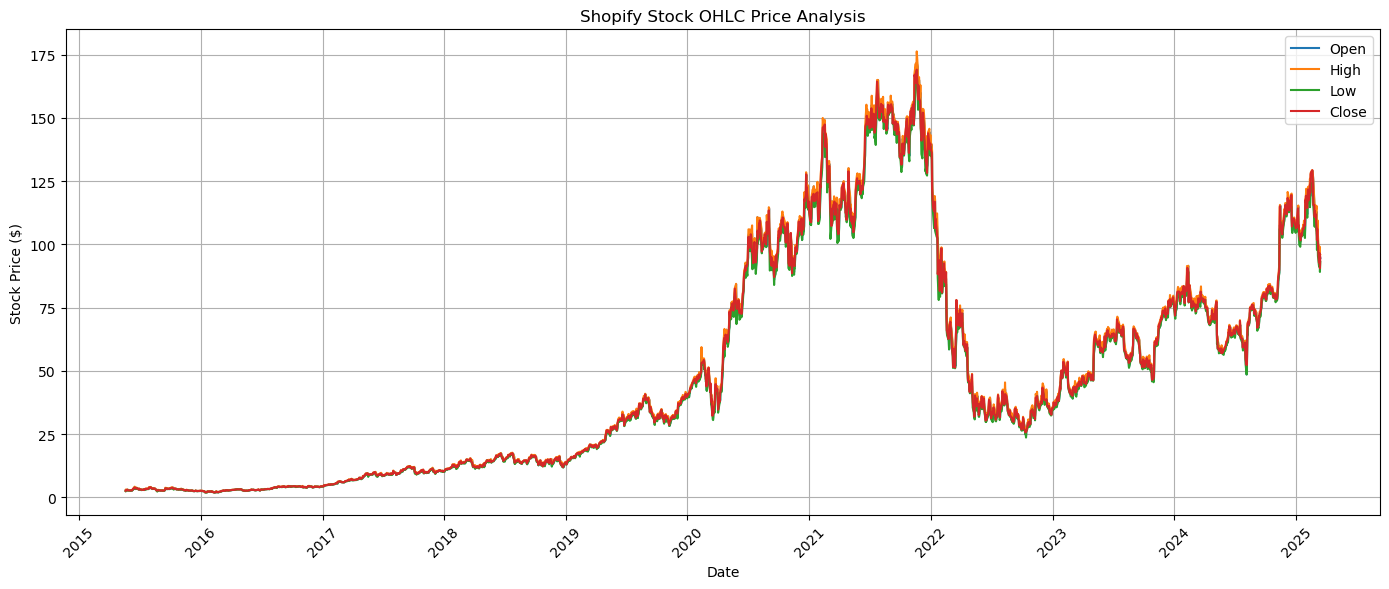

In [52]:
plt.figure(figsize=(14, 6))

plt.plot(df['date'], df['open'], label='Open')
plt.plot(df['date'], df['high'], label='High')
plt.plot(df['date'], df['low'], label='Low')
plt.plot(df['date'], df['close'], label='Close')

plt.title('Shopify Stock OHLC Price Analysis')
plt.xlabel('Date')
plt.ylabel('Stock Price ($)')

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Simple Moving Average (SMA) Analysis ##

In [53]:
df['SMA_20'] = df['close'].rolling(window=20).mean()
df['SMA_50'] = df['close'].rolling(window=50).mean()

display(df[['date', 'close', 'SMA_20', 'SMA_50']].tail(10))

,date,close,SMA_20,SMA_50
2459,2025-03-03 00:00:00-05:00,106.580002,118.818001,112.7920
2460,2025-03-04 00:00:00-05:00,101.730003,118.185001,112.4368
2461,2025-03-05 00:00:00-05:00,106.150002,117.532501,112.3658
2462,2025-03-06 00:00:00-05:00,102.489998,116.570501,112.2742
2463,2025-03-07 00:00:00-05:00,100.129997,115.648001,112.0978
2464,2025-03-10 00:00:00-04:00,92.750000,114.415001,111.7678
2465,2025-03-11 00:00:00-04:00,92.949997,113.067500,111.4232
2466,2025-03-12 00:00:00-04:00,96.529999,111.714500,111.1546
2467,2025-03-13 00:00:00-04:00,90.589996,110.219500,110.8028
2468,2025-03-14 00:00:00-04:00,94.849998,108.579500,110.5660


## Visualize Moving Averages ##

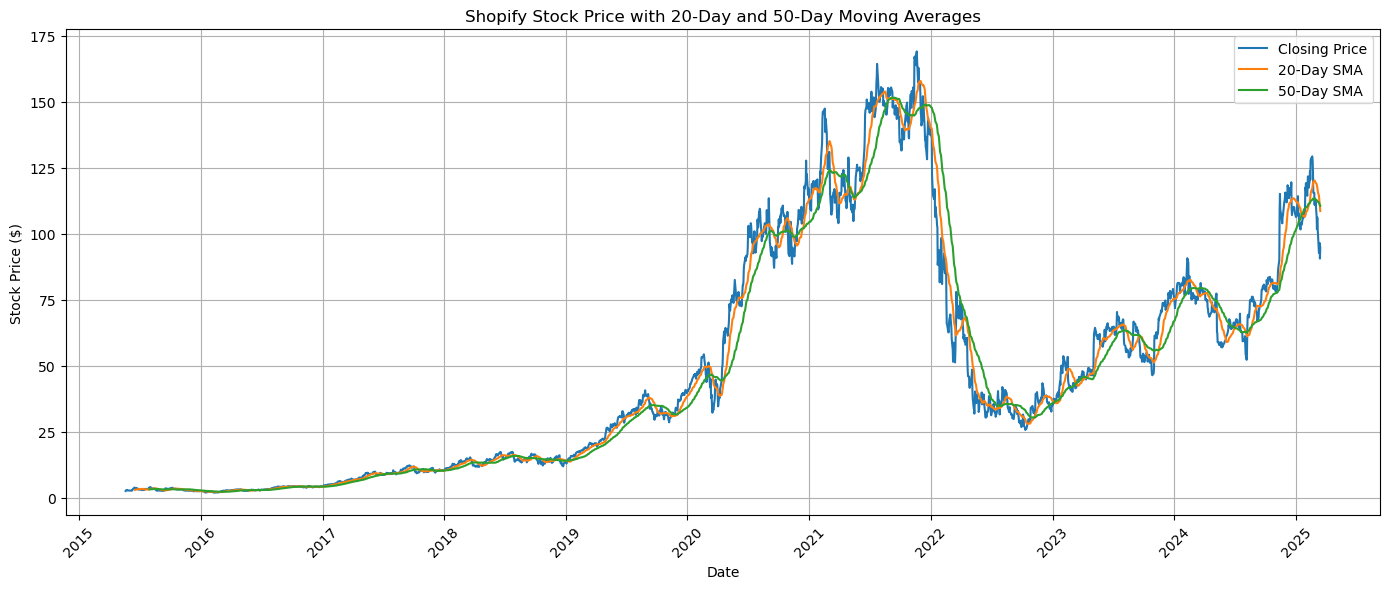

In [55]:
plt.figure(figsize=(14, 6))

plt.plot(df['date'], df['close'], label='Closing Price')
plt.plot(df['date'], df['SMA_20'], label='20-Day SMA')
plt.plot(df['date'], df['SMA_50'], label='50-Day SMA')

plt.title('Shopify Stock Price with 20-Day and 50-Day Moving Averages')
plt.xlabel('Date')
plt.ylabel('Stock Price ($)')

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Histogram Plot ##

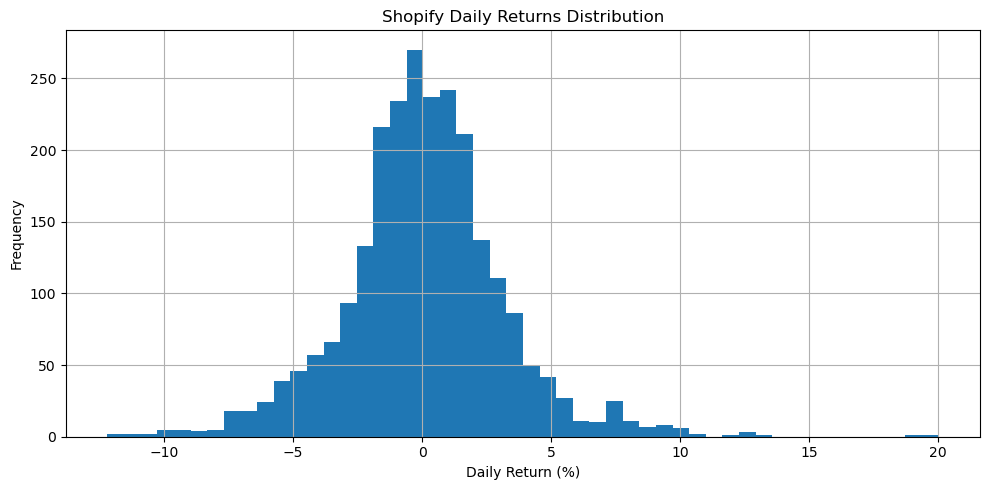

In [56]:
plt.figure(figsize=(10, 5))

plt.hist(df['daily_return'].dropna(), bins=50)

plt.title('Shopify Daily Returns Distribution')
plt.xlabel('Daily Return (%)')
plt.ylabel('Frequency')

plt.grid(True)
plt.tight_layout()
plt.show()


## KDE Plot ##

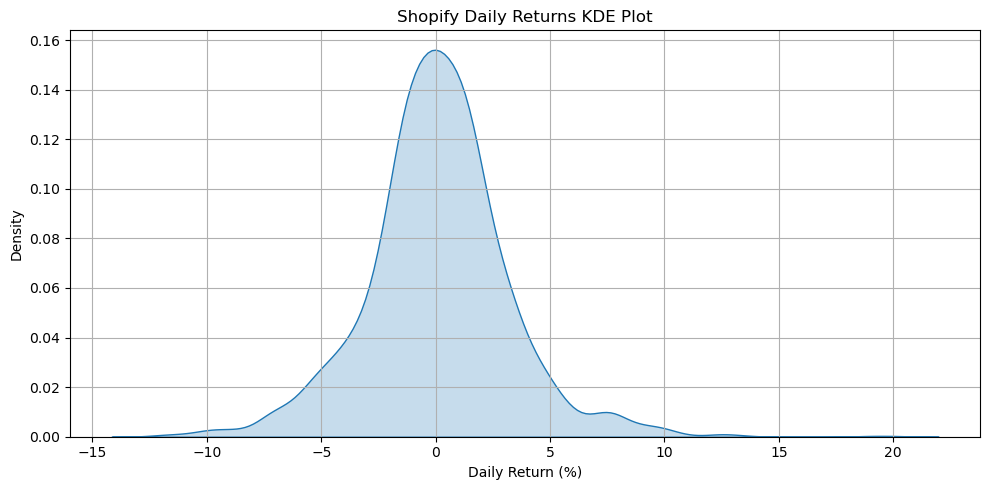

In [57]:
plt.figure(figsize=(10, 5))

sns.kdeplot(data=df, x='daily_return', fill=True)

plt.title('Shopify Daily Returns KDE Plot')
plt.xlabel('Daily Return (%)')
plt.ylabel('Density')

plt.grid(True)
plt.tight_layout()
plt.show()

In [58]:
#Relationship Analysis

#Correlation Analysis

relationship_data = df[
    ['volume', 'daily_price_change', 'price_fluctuation_pct']
]

correlation_matrix = relationship_data.corr()

print("Relationship Between Trading Volume, Price Change and Volatility:")
display(correlation_matrix)

Relationship Between Trading Volume, Price Change and Volatility:


,volume,daily_price_change,price_fluctuation_pct
volume,1.000000,0.008303,0.569037
daily_price_change,0.008303,1.000000,-0.036662
price_fluctuation_pct,0.569037,-0.036662,1.000000


## Correlation Heatmap ##

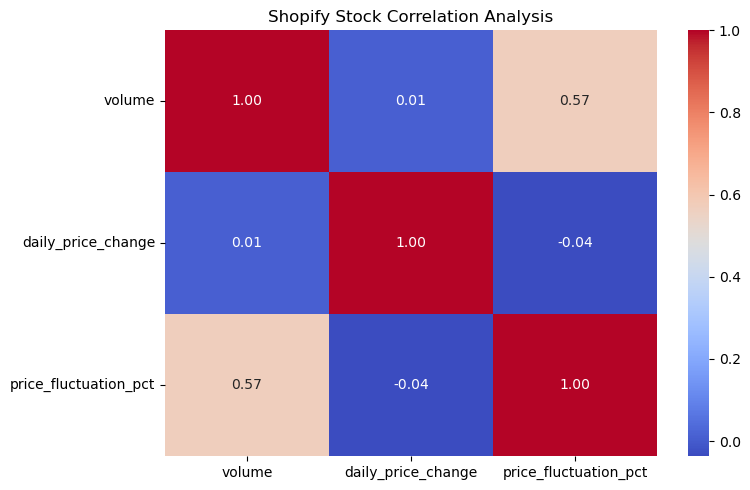

In [60]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Shopify Stock Correlation Analysis')
plt.tight_layout()
plt.show()

## Scatter Plot Analysis ##

Trading Volume vs Price Change

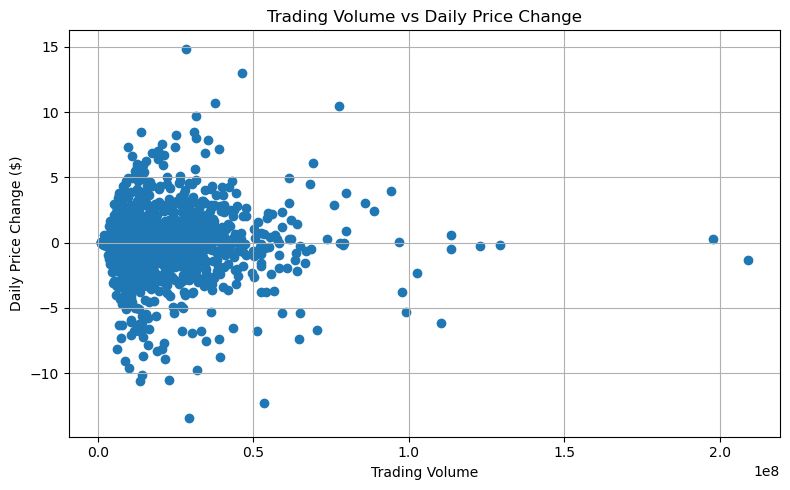

In [61]:
plt.figure(figsize=(8, 5))

plt.scatter(df['volume'], df['daily_price_change'])

plt.title('Trading Volume vs Daily Price Change')
plt.xlabel('Trading Volume')
plt.ylabel('Daily Price Change ($)')

plt.grid(True)
plt.tight_layout()
plt.show()

Trading Volume vs Price Volatility

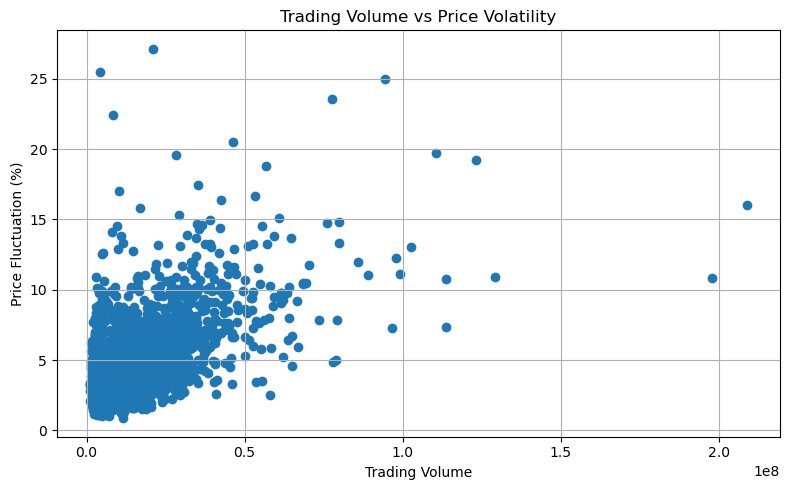

In [62]:
plt.figure(figsize=(8, 5))

plt.scatter(df['volume'], df['price_fluctuation_pct'])

plt.title('Trading Volume vs Price Volatility')
plt.xlabel('Trading Volume')
plt.ylabel('Price Fluctuation (%)')

plt.grid(True)
plt.tight_layout()
plt.show()

# Shopify Stock Market Analysis – Financial Summary Report #

# 1. Introduction #

This project focuses on analysing Shopify stock market data using Python. The analysis covers historical stock prices, trading volume, daily returns, price fluctuations and moving averages.

# 2. Stock Price Analysis #

The Open, High, Low and Close (OHLC) values were analysed to understand Shopify's historical stock price movements.

A time-series line plot was created to visualize changes in stock prices over time.

## 3. Trading Volume Analysis ##

Trading volume was analysed using statistical measures such as mean, median, minimum, maximum and standard deviation.

Unusual trading volume records were also identified using the Interquartile Range (IQR) method.

## 4. Daily Return Analysis ##

Daily price change and daily return percentage were calculated to understand the daily movement of Shopify stock prices.

The mean, variance and standard deviation were used to study the distribution of daily returns.

## 5. Price Volatility Analysis ##

Price volatility was examined using the difference between daily high and low prices.

The days with higher price fluctuations were identified to understand periods of increased market volatility.

## 6. Moving Average Analysis ##

The 20-day and 50-day Simple Moving Averages (SMA) were calculated using closing prices.

These moving averages were plotted alongside closing prices to observe historical price trends

## 7. Correlation Analysis ##

Correlation analysis was performed to examine the relationships between trading volume, daily price change and price volatility.

Heatmaps and scatter plots were used to visualize these relationships.

## 8. Daily Return Distribution ##

A histogram and Kernel Density Estimation (KDE) plot were created to understand the distribution of daily returns.

These visualizations help examine the spread and shape of stock returns.

## 9. Conclusion ##

The Shopify Stock Market Analysis project helped explore historical stock market data using Python.

Data cleaning, feature engineering, statistical analysis and data visualization techniques were applied to understand stock price movements, trading volume, daily returns and market volatility.

The project provided practical experience in Exploratory Data Analysis (EDA) and time-series data visualization.